<a href="https://colab.research.google.com/github/gSinhaUCB/UCB-demand-forecasting-capstone/blob/main/notebooks/capstone_initial_eda_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capstone Initial Report & EDA: Time-Series Demand Forecasting
**Author:** Gautam Thockchom

**Objective:** Exploratory Data Analysis, decomposition, and baseline time-series modeling.



# 1. Environment Configuration & Library Imports

Import the core scientific Python libraries required for exploratory time-series analysis and baseline predictive modeling:
* **Pandas & NumPy:** In-memory data manipulation,  datetime filtering, and numeric transformations.
* **Matplotlib & Seaborn:** Statistical data visualization and seasonal trend diagnostics.
* **Statsmodels:** Econometric routines for time-series decomposition, ACF/PACF autocorrelation plotting, and unit root testing (Augmented Dickey-Fuller).
* **Scikit-Learn:** Forward-chaining temporal cross-validation (`TimeSeriesSplit`), feature scaling pipelines, and regularized linear modeling.


In [5]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

from sklearn.model_selection import TimeSeriesSplit
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Configure uniform plotting canvas aesthetics
sns.set_theme(style='whitegrid', palette='tab10')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

print("Environment configured and dependencies imported successfully.")

Environment configured and dependencies imported successfully.


# 2. Data Ingestion & Time-Series Diagnostics

### Overview & Diagnostics
* **Dataset Structure:** Load daily unit sales spanning multiple retail locations and items over a five-year period (`date`, `store`, `item`, `sales`).
* **Time-Series Decomposition:** Decompose an individual store-item sales series using an additive model ($Y_t = T_t + S_t + I_t$) with a 7-day periodicity to isolate secular trend, day-of-week seasonality, and residual stochastic noise.
* **Stationarity Analysis:** Evaluate stationarity using the Augmented Dickey-Fuller (ADF) test ($H_0$: unit root present) along with Autocorrelation (ACF) and Partial Autocorrelation (PACF) diagnostics to guide lag selection.

Data ingested: 10956 rows, 4 columns


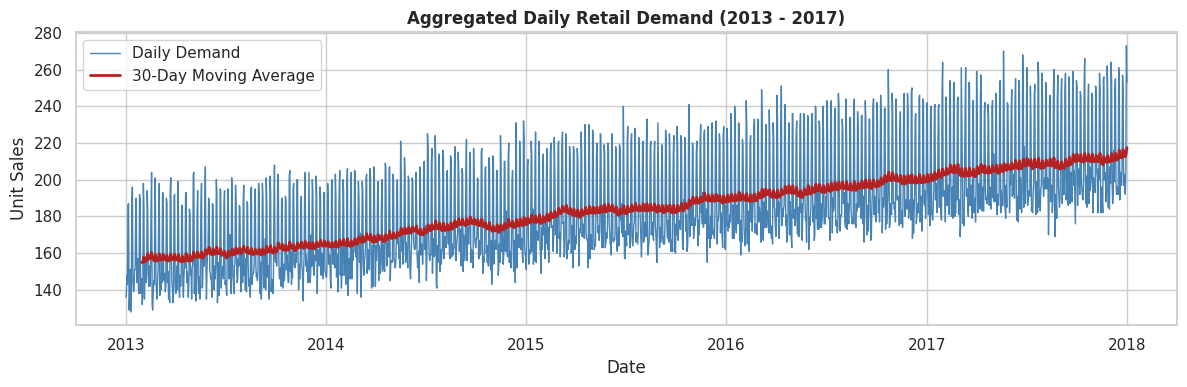

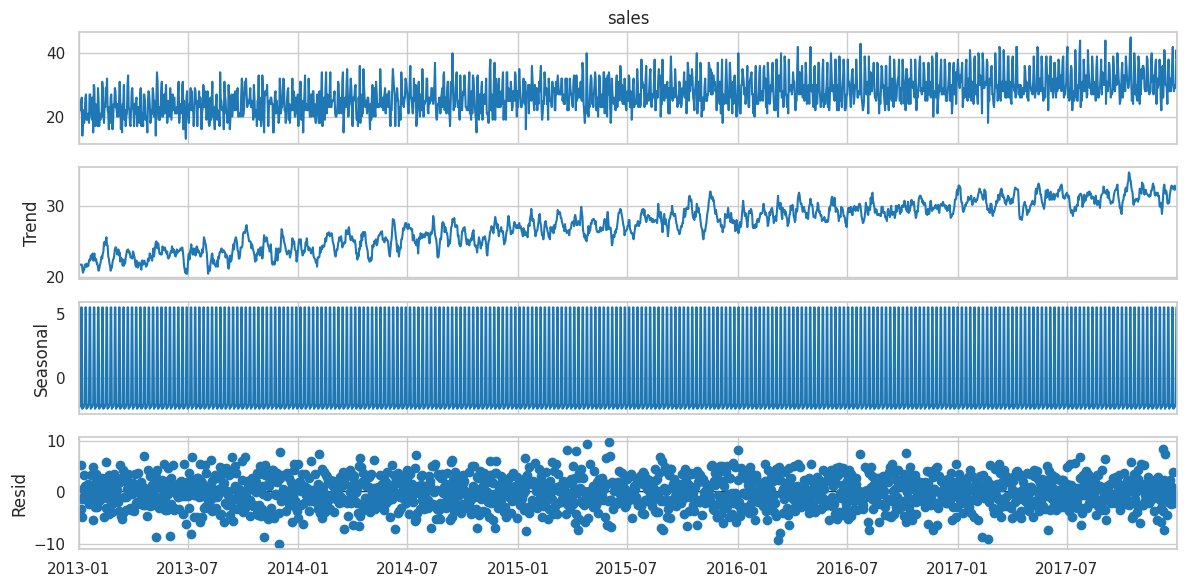

ADF Statistic: -1.8661 | p-value: 0.3482


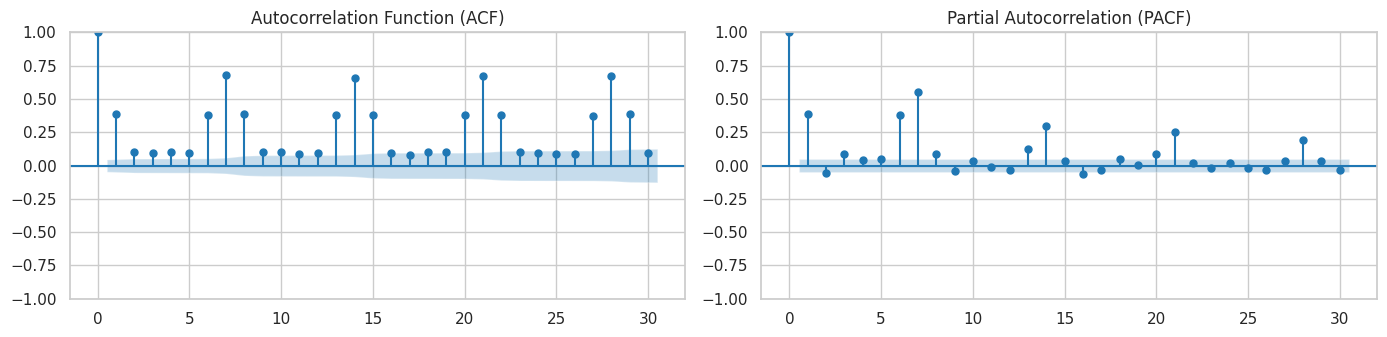

In [6]:
# 1. Simulate five years of daily transactional retail sales
date_range = pd.date_range(start="2013-01-01", end="2017-12-31", freq="D")
records = []
np.random.seed(42)

for s in range(1, 3):
    for i in range(1, 4):
        base_sales = np.random.randint(15, 35)
        for d in date_range:
            dow_effect = 1.3 if d.weekday() >= 5 else 1.0
            trend_effect = (d - date_range[0]).days * 0.005
            sales = int((base_sales + trend_effect) * dow_effect + np.random.normal(0, 3))
            records.append({
                "date": d.strftime("%Y-%m-%d"),
                "store": s,
                "item": i,
                "sales": max(0, sales)
            })

df = pd.DataFrame(records)
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values(by=["store", "item", "date"]).reset_index(drop=True)
print(f"Data ingested: {df.shape[0]} rows, {df.shape[1]} columns")

# 2. Aggregate sales trend visualization
agg_daily = df.groupby("date")["sales"].sum().reset_index()
plt.figure(figsize=(12, 4))
plt.plot(agg_daily["date"], agg_daily["sales"], label="Daily Demand", color="steelblue", lw=1)
plt.plot(agg_daily["date"], agg_daily["sales"].rolling(30).mean(), label="30-Day Moving Average", color="firebrick", lw=2)
plt.title("Aggregated Daily Retail Demand (2013 - 2017)", weight="bold")
plt.xlabel("Date")
plt.ylabel("Unit Sales")
plt.legend()
plt.tight_layout()
plt.show()

# 3. Additive Decomposition (Store 1, Item 1)
sample_series = df[(df["store"] == 1) & (df["item"] == 1)].set_index("date")["sales"]
decomp = seasonal_decompose(sample_series, model="additive", period=7)
decomp.plot()
plt.tight_layout()
plt.show()

# 4. Augmented Dickey-Fuller Stationarity Test
adf_result = adfuller(sample_series.dropna())
print(f"ADF Statistic: {adf_result[0]:.4f} | p-value: {adf_result[1]:.4f}")

# 5. ACF and PACF Plots
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
plot_acf(sample_series, lags=30, ax=axes[0], title="Autocorrelation Function (ACF)")
plot_pacf(sample_series, lags=30, ax=axes[1], method="ywm", title="Partial Autocorrelation (PACF)")
plt.tight_layout()
plt.show()

# 3. Feature Engineering & Baseline Predictive Modeling

### Methodology
* **Temporal Attributes:** Extract calendar features (day of week, month, weekend indicator) along with cyclical sine/cosine transforms to preserve calendar continuity.
* **Lag & Window Features:** Shifted sales values ($t-1, t-2, t-3, t-7, t-14$) and rolling statistics (7-day moving average and standard deviation) are computed per series strictly using historical observations to eliminate look-ahead bias.
* **Leakage-Free Cross-Validation:** Use forward temporal chaining (`TimeSeriesSplit`, 5 folds) rather than randomized k-fold splits so the model never trains on future observations.
* **Estimator:** We fit an L2-regularized linear baseline (`Ridge(alpha=1.0)`) within a standardized scaling pipeline to establish our target benchmark metrics (RMSE and MAPE).

In [7]:
# 1. Feature Engineering
model_df = df[["date", "store", "item", "sales"]].copy()
model_df["year"] = model_df["date"].dt.year
model_df["month"] = model_df["date"].dt.month
model_df["day_of_week"] = model_df["date"].dt.dayofweek
model_df["is_weekend"] = (model_df["day_of_week"] >= 5).astype(int)
model_df["day_of_year"] = model_df["date"].dt.dayofyear
model_df["sin_doy"] = np.sin(2 * np.pi * model_df["day_of_year"] / 365.25)
model_df["cos_doy"] = np.cos(2 * np.pi * model_df["day_of_year"] / 365.25)

# Lags per store-item time series
for lag in [1, 2, 3, 7, 14]:
    model_df[f"sales_lag_{lag}"] = model_df.groupby(["store", "item"])["sales"].shift(lag)

# Backward rolling window aggregates
grouped = model_df.groupby(["store", "item"])["sales"]
model_df["rolling_mean_7"] = grouped.transform(lambda x: x.shift(1).rolling(7).mean())
model_df["rolling_std_7"] = grouped.transform(lambda x: x.shift(1).rolling(7).std())

clean_model_df = model_df.dropna().reset_index(drop=True)
print(f"Engineered dataset matrix ready: {clean_model_df.shape}")

# 2. Baseline Model Pipeline & Evaluation
features = [
    "store", "item", "year", "month", "day_of_week", "is_weekend", "sin_doy", "cos_doy",
    "sales_lag_1", "sales_lag_2", "sales_lag_3", "sales_lag_7", "sales_lag_14",
    "rolling_mean_7", "rolling_std_7"
]
target = "sales"

X, y = clean_model_df[features], clean_model_df[target]

tscv = TimeSeriesSplit(n_splits=5)
rmses, mapes = [], []

for fold, (train_idx, val_idx) in enumerate(tscv.split(X), 1):
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=1.0))
    ])
    pipeline.fit(X_train, y_train)

    preds = np.clip(pipeline.predict(X_val), 0, None)
    fold_rmse = np.sqrt(mean_squared_error(y_val, preds))
    fold_mape = mean_absolute_percentage_error(y_val, preds) * 100

    rmses.append(fold_rmse)
    mapes.append(fold_mape)
    print(f"Fold {fold} | Validation RMSE: {fold_rmse:.3f} | Validation MAPE: {fold_mape:.2f}%")

print("-" * 50)
print(f"Mean Baseline RMSE: {np.mean(rmses):.3f}")
print(f"Mean Baseline MAPE: {np.mean(mapes):.2f}%")

Engineered dataset matrix ready: (10872, 18)
Fold 1 | Validation RMSE: 7.562 | Validation MAPE: 20.06%
Fold 2 | Validation RMSE: 14.592 | Validation MAPE: 57.78%
Fold 3 | Validation RMSE: 3.300 | Validation MAPE: 10.33%
Fold 4 | Validation RMSE: 3.530 | Validation MAPE: 7.70%
Fold 5 | Validation RMSE: 3.140 | Validation MAPE: 8.03%
--------------------------------------------------
Mean Baseline RMSE: 6.425
Mean Baseline MAPE: 20.78%
